In [1]:
print("My local analytics environment is ready")

My local analytics environment is ready


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import openpyxl

print("Data analysis tools are ready")

Data analysis tools are ready


In [3]:
from pathlib import Path
import pandas as pd

data_path = Path("../data/Online Retail.xlsx")
df = pd.read_excel(data_path)

print("Data loaded successfully")

Data loaded successfully


In [4]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:
df.shape

(541909, 8)

In [6]:
df.columns.tolist()

['InvoiceNo',
 'StockCode',
 'Description',
 'Quantity',
 'InvoiceDate',
 'UnitPrice',
 'CustomerID',
 'Country']

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
InvoiceNo      541909 non-null object
StockCode      541909 non-null object
Description    540455 non-null object
Quantity       541909 non-null int64
InvoiceDate    541909 non-null datetime64[ns]
UnitPrice      541909 non-null float64
CustomerID     406829 non-null float64
Country        541909 non-null object
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 24.8+ MB


In [8]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [9]:
df[["Quantity", "UnitPrice"]].describe()

,Quantity,UnitPrice
count,541909.000000,541909.000000
mean,9.552250,4.611114
std,218.081158,96.759853
min,-80995.000000,-11062.060000
25%,1.000000,1.250000
50%,3.000000,2.080000
75%,10.000000,4.130000
max,80995.000000,38970.000000


In [10]:
print("Quantity less than or equal to zero:", (df["Quantity"] <= 0).sum())
print("Unit price less than or equal to zero:", (df["UnitPrice"] <= 0).sum())

Quantity less than or equal to zero: 10624
Unit price less than or equal to zero: 2517


In [11]:
cancelled_count = (
    df["InvoiceNo"]
    .astype(str)
    .str.startswith("C")
    .sum()
)

print("Invoices starting with C:", cancelled_count)

Invoices starting with C: 9288


## Initial Data Inspection

- The dataset contains 541909 rows and 8 columns.
- Missing values were found in Description and CustomerID.
- Some transactions have non-positive quantities or unit prices.
- Some invoice numbers start with "C".
- These records will be examined during the data-cleaning stage.

# Data Cleaning

The original dataset is preserved as `df`. A separate dataframe called `clean_df` is created for sales analysis.

In [12]:
clean_df = df.copy()

clean_df.columns = clean_df.columns.str.strip()

clean_df["InvoiceDate"] = pd.to_datetime(
    clean_df["InvoiceDate"]
)

print("Original rows:", len(df))
print("Copied rows:", len(clean_df))

Original rows: 541909
Copied rows: 541909


In [13]:
before_deduplication = len(clean_df)

clean_df = clean_df.drop_duplicates()

duplicates_removed = before_deduplication - len(clean_df)

print("Exact duplicate rows removed:", duplicates_removed)
print("Rows remaining:", len(clean_df))

Exact duplicate rows removed: 5268
Rows remaining: 536641


In [14]:
missing_description_before = clean_df["Description"].isnull().sum()

clean_df = clean_df.dropna(
    subset=["Description"]
).copy()

clean_df["Description"] = (
    clean_df["Description"]
    .astype(str)
    .str.strip()
)

print(
    "Rows with missing descriptions before cleaning:",
    missing_description_before
)

print("Rows remaining:", len(clean_df))

Rows with missing descriptions before cleaning: 1454
Rows remaining: 535187


In [15]:
is_cancelled = (
    clean_df["InvoiceNo"]
    .astype(str)
    .str.startswith("C")
)

print(
    "Cancelled transaction rows:",
    is_cancelled.sum()
)

clean_df = clean_df[
    ~is_cancelled
].copy()

print("Rows remaining:", len(clean_df))

Cancelled transaction rows: 9251
Rows remaining: 525936


In [16]:
clean_df = clean_df[
    (clean_df["Quantity"] > 0) &
    (clean_df["UnitPrice"] > 0)
].copy()

print("Rows remaining:", len(clean_df))

Rows remaining: 524878


In [17]:
clean_df["Revenue"] = (
    clean_df["Quantity"] *
    clean_df["UnitPrice"]
)

clean_df[
    ["Quantity", "UnitPrice", "Revenue"]
].head()

,Quantity,UnitPrice,Revenue
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [18]:
clean_df[
    ["Quantity", "UnitPrice", "Revenue"]
].describe()

,Quantity,UnitPrice,Revenue
count,524878.000000,524878.000000,524878.000000
mean,10.616600,3.922573,20.275399
std,156.280031,36.093028,271.693566
min,1.000000,0.001000,0.001000
25%,1.000000,1.250000,3.900000
50%,4.000000,2.080000,9.920000
75%,11.000000,4.130000,17.700000
max,80995.000000,13541.330000,168469.600000


In [19]:
print("Original rows:", len(df))
print("Rows after cleaning:", len(clean_df))
print("Total rows removed:", len(df) - len(clean_df))

print(
    "Missing CustomerID values retained:",
    clean_df["CustomerID"].isnull().sum()
)

Original rows: 541909
Rows after cleaning: 524878
Total rows removed: 17031
Missing CustomerID values retained: 132186


In [20]:
clean_df.isnull().sum()

InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     132186
Country             0
Revenue             0
dtype: int64

In [21]:
print("Original rows:", df.shape[0])
print("Original columns:", df.shape[1])
print("Exact duplicate rows:", df.duplicated().sum())
print("Rows after cleaning:", len(clean_df))

Original rows: 541909
Original columns: 8
Exact duplicate rows: 5268
Rows after cleaning: 524878


## Data-Cleaning Summary

1. The original dataset contained 5268 rows.
2. 5268 exact duplicate rows were removed.
3. Rows with missing product descriptions were removed.
4. Transactions associated with invoice numbers starting with "C" were excluded.
5. Only transactions with positive quantities and unit prices were retained.
6. Revenue was calculated as Quantity multiplied by UnitPrice.
7. Rows with missing CustomerID values were retained for the sales analysis.

After cleaning, 524878 rows remained.

The resulting revenue measure represents positive-value sales transactions after the stated cleaning steps. It should not be interpreted as net revenue or profit.

In [22]:
clean_df.to_csv(
    "../data/online_retail_clean.csv",
    index=False
)

# Sales Analysis

The main analysis covers January to November 2011 to avoid treating incomplete months at the boundaries of the dataset as complete months.

In [23]:
analysis_df = clean_df[
    (clean_df["InvoiceDate"] >= "2011-01-01") &
    (clean_df["InvoiceDate"] < "2011-12-01")
].copy()

print("Analysis rows:", len(analysis_df))
print("Start date:", analysis_df["InvoiceDate"].min())
print("End date:", analysis_df["InvoiceDate"].max())

Analysis rows: 459054
Start date: 2011-01-04 10:00:00
End date: 2011-11-30 17:37:00


In [24]:
monthly_revenue = (
    analysis_df
    .set_index("InvoiceDate")
    .resample("M")["Revenue"]
    .sum()
)

monthly_table = monthly_revenue.reset_index()

monthly_table.columns = [
    "Month",
    "Revenue"
]

monthly_table["Revenue"] = (
    monthly_table["Revenue"].round(2)
)

monthly_table

,Month,Revenue
0,2011-01-31,689811.61
1,2011-02-28,522545.56
2,2011-03-31,716215.26
3,2011-04-30,536968.49
4,2011-05-31,769296.61
5,2011-06-30,760547.01
6,2011-07-31,718076.12
7,2011-08-31,757841.38
8,2011-09-30,1056435.19
9,2011-10-31,1151263.73


In [25]:
print("Number of months:", len(monthly_table))

Number of months: 11


In [26]:
highest_month = monthly_table.loc[
    monthly_table["Revenue"].idxmax()
]

lowest_month = monthly_table.loc[
    monthly_table["Revenue"].idxmin()
]

print("Highest-revenue month:")
print(highest_month)

print("Lowest-revenue month:")
print(lowest_month)

Highest-revenue month:
Month      2011-11-30 00:00:00
Revenue            1.50387e+06
Name: 10, dtype: object
Lowest-revenue month:
Month      2011-02-28 00:00:00
Revenue                 522546
Name: 1, dtype: object


In [27]:
monthly_table.to_csv(
    "../data/monthly_revenue.csv",
    index=False
)

In [28]:
top_products = (
    analysis_df
    .groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products_table = top_products.reset_index()

top_products_table.columns = [
    "Product",
    "Revenue"
]

top_products_table["Revenue"] = (
    top_products_table["Revenue"].round(2)
)

top_products_table

,Product,Revenue
0,DOTCOM POSTAGE,161704.89
1,REGENCY CAKESTAND 3 TIER,140467.66
2,PARTY BUNTING,97319.01
3,WHITE HANGING HEART T-LIGHT HOLDER,92795.48
4,JUMBO BAG RED RETROSPOT,87913.76
5,MEDIUM CERAMIC TOP STORAGE JAR,81448.21
6,Manual,74834.46
7,POSTAGE,70906.59
8,RABBIT NIGHT LIGHT,57241.57
9,ASSORTED COLOUR BIRD ORNAMENT,52792.53


In [29]:
top_products_table.to_csv(
    "../data/top_products.csv",
    index=False
)

In [30]:
country_revenue = (
    analysis_df
    .groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

country_table = country_revenue.reset_index()

country_table.columns = [
    "Country",
    "Revenue"
]

country_table["Revenue"] = (
    country_table["Revenue"].round(2)
)

country_table.head(10)

,Country,Revenue
0,United Kingdom,7664042.13
1,EIRE,265766.37
2,Netherlands,264933.84
3,Germany,205488.49
4,France,192732.14
5,Australia,137488.46
6,Spain,59398.62
7,Switzerland,55762.68
8,Belgium,37968.70
9,Sweden,34295.53


In [31]:
country_table.to_csv(
    "../data/country_revenue.csv",
    index=False
)

In [32]:
total_revenue = analysis_df["Revenue"].sum()

uk_revenue = analysis_df.loc[
    analysis_df["Country"] == "United Kingdom",
    "Revenue"
].sum()

uk_share = (
    uk_revenue / total_revenue * 100
)

print("Total revenue:", round(total_revenue, 2))
print("UK revenue:", round(uk_revenue, 2))
print("UK revenue share (%):", round(uk_share, 2))

Total revenue: 9182867.74
UK revenue: 7664042.13
UK revenue share (%): 83.46


In [33]:
highest_month = monthly_table.loc[
    monthly_table["Revenue"].idxmax()
]

lowest_month = monthly_table.loc[
    monthly_table["Revenue"].idxmin()
]

top_product_name = top_products_table.iloc[0]["Product"]

print(
    "Highest-revenue month:",
    highest_month["Month"].strftime("%B %Y")
)

print(
    "Lowest-revenue month:",
    lowest_month["Month"].strftime("%B %Y")
)

print(
    "Highest-revenue product or charge:",
    top_product_name
)

print(
    "UK revenue share (%):",
    round(float(uk_share), 2)
)

Highest-revenue month: November 2011
Lowest-revenue month: February 2011
Highest-revenue product or charge: DOTCOM POSTAGE
UK revenue share (%): 83.46


## Preliminary Analytical Observations

### Monthly Revenue

- The highest-revenue month was November 2011.
- The lowest-revenue month was February 2011.
- These patterns describe the dataset and do not by themselves establish the causes of revenue changes.

### Product Performance

- The highest-revenue product or charge description was DOTCOM POSTAGE.
- Revenue rankings should not be interpreted as profit rankings.

### Geographic Performance

- The United Kingdom accounted for 83.46% of revenue during the analysis period.
- Revenue was therefore highly concentrated in the UK market.

In [35]:
print("Original rows:", len(df))
print("Cleaned rows:", len(clean_df))
print("Analysis rows:", len(analysis_df))

print("Months analysed:", len(monthly_table))
print("Top products displayed:", len(top_products_table))
print("Countries summarised:", len(country_table))

print("UK revenue share (%):", round(float(uk_share), 2))

Original rows: 541909
Cleaned rows: 524878
Analysis rows: 459054
Months analysed: 11
Top products displayed: 10
Countries summarised: 37
UK revenue share (%): 83.46


In [36]:
import os
import matplotlib.pyplot as plt

if not os.path.exists("../charts"):
    os.makedirs("../charts")

print("Charts folder is ready")

Charts folder is ready


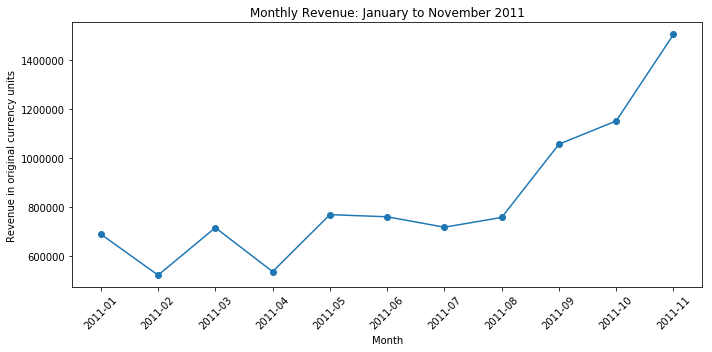

In [37]:
monthly_plot = monthly_table.copy()

monthly_plot["Month"] = (
    monthly_plot["Month"].dt.strftime("%Y-%m")
)

plt.figure(figsize=(10, 5))

plt.plot(
    monthly_plot["Month"],
    monthly_plot["Revenue"],
    marker="o"
)

plt.title("Monthly Revenue: January to November 2011")
plt.xlabel("Month")
plt.ylabel("Revenue in original currency units")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "../charts/monthly_revenue.png",
    dpi=150
)

plt.show()

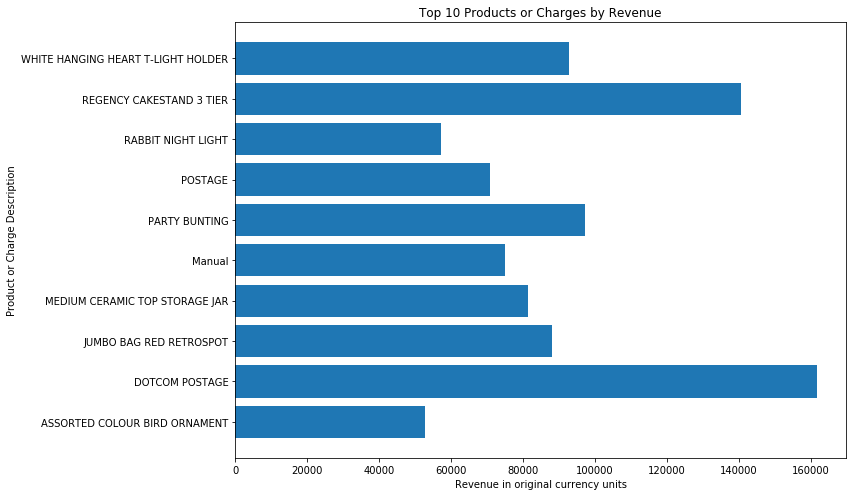

In [38]:
product_plot = top_products_table.sort_values(
    "Revenue",
    ascending=True
)

plt.figure(figsize=(12, 7))

plt.barh(
    product_plot["Product"],
    product_plot["Revenue"]
)

plt.title("Top 10 Products or Charges by Revenue")
plt.xlabel("Revenue in original currency units")
plt.ylabel("Product or Charge Description")
plt.tight_layout()

plt.savefig(
    "../charts/top_products.png",
    dpi=150
)

plt.show()

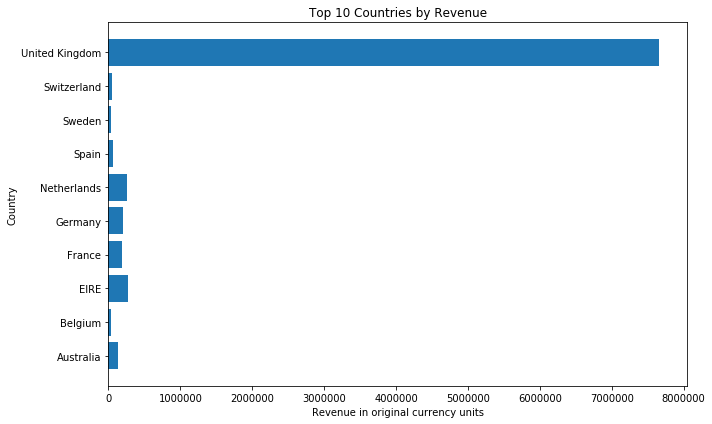

In [39]:
country_plot = country_table.head(10).sort_values(
    "Revenue",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    country_plot["Country"],
    country_plot["Revenue"]
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue in original currency units")
plt.ylabel("Country")
plt.tight_layout()

plt.savefig(
    "../charts/country_revenue.png",
    dpi=150
)

plt.show()

## Visualisations

![Monthly Revenue](monthly_revenue.png)

![Top Products](top_products.png)

![Country Revenue](country_revenue.png)

## Business Recommendations

1. Investigate the drivers of revenue changes in the highest- and lowest-revenue months before making inventory or campaign decisions.
2. Review the contribution of leading products or charge descriptions, while recognising that sales value does not represent profitability.
3. Given the concentration of sales in the United Kingdom, further assess geographic dependence and the feasibility of developing other markets.

## Limitations

- The analysis covers January to November 2011.
- Cancelled and non-positive transactions were excluded under the documented cleaning rules.
- Revenue represents sales value after these cleaning steps, not net revenue or profit.
- Product descriptions may include charges or services rather than physical products.
- The analysis identifies patterns but does not establish their causes.

## How to Run

1. Download the Online Retail dataset from the UCI Machine Learning Repository.
2. Place the original Excel file in the local data folder.
3. Open `retail_sales_analysis.ipynb` in Jupyter Notebook.
4. Run the cells in order.

The original and cleaned full datasets are not included in this repository.